Saving loan_data5.csv to loan_data5.csv

===== Decision Tree =====
Accuracy: 0.9333333333333333
Precision: 0.9473684210526315
Recall: 0.9473684210526315
F1-Score: 0.9473684210526315

Classification Report:

              precision    recall  f1-score   support

           0       0.91      0.91      0.91        11
           1       0.95      0.95      0.95        19

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Confusion Matrix:
 [[10  1]
 [ 1 18]]


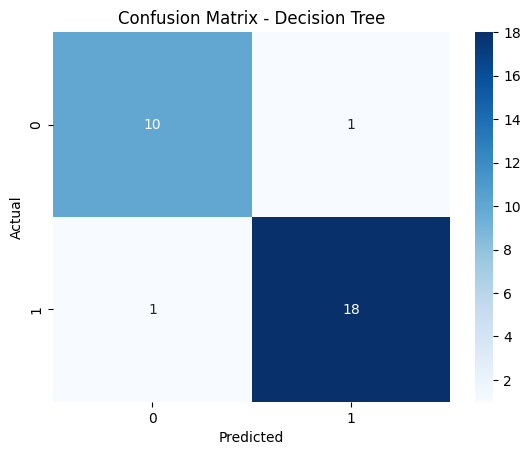


===== Random Forest =====
Accuracy: 0.8666666666666667
Precision: 0.8947368421052632
Recall: 0.8947368421052632
F1-Score: 0.8947368421052632

Classification Report:

              precision    recall  f1-score   support

           0       0.82      0.82      0.82        11
           1       0.89      0.89      0.89        19

    accuracy                           0.87        30
   macro avg       0.86      0.86      0.86        30
weighted avg       0.87      0.87      0.87        30

Confusion Matrix:
 [[ 9  2]
 [ 2 17]]


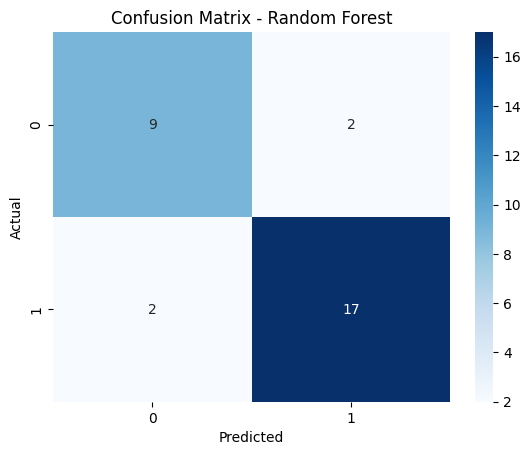

In [ ]:
from google.colab import files
uploaded = files.upload()
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, \
precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve
import matplotlib.pyplot as plt
loan = pd.read_csv("loan_data5.csv")
# Data Preprocessing
# Remove missing values
loan.dropna(inplace=True)
# Separate target column
y = loan['Loan_Status']   # Target column
X = loan.drop('Loan_Status', axis=1)
# Convert categorical features to numeric
X = pd.get_dummies(X, drop_first=True)

# Convert target column (Y=1, N=0)
y = y.map({'Y': 1, 'N': 0})
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
# --------------------------------------------------
# Decision Tree Classifier
# --------------------------------------------------
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

# --------------------------------------------------
# Random Forest Classifier
# --------------------------------------------------
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# --------------------------------------------------
# Evaluation Function
# --------------------------------------------------
def evaluate_model(y_test, y_pred, model_name):

    print(f"\n===== {model_name} =====")

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1-Score:", f1)

    print("\nClassification Report:\n")
    print(classification_report(y_test, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:\n", cm)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

# --------------------------------------------------
# Evaluate Both Models
# --------------------------------------------------
evaluate_model(y_test, y_pred_dt, "Decision Tree")
evaluate_model(y_test, y_pred_rf, "Random Forest")


